# Coach pressers: what is in the vectors beyond the numbers we already have?

The first notebook showed that the top components are the result and the
transcript's length. This one asks the question that matters for features:
**after removing what is already known as numbers** (transcript length and
season, box score, regulars out, record, closing line), is there anything
repeatable left, and which text and instruction keep most of it?

There is no label for "intensity" or "style", so the residual is judged by
agreement between independent views of the same thing:

- **halves**: odd and even chunks of the same presser (upper bound: also true
  for a coach's wording);
- **game**: the two coaches of the same game. Two people, two teams, one game.
  This is the measure that matters.

Both are an AUC: the probability that a matched pair is closer than an
unmatched one (0.5 = nothing). Vectors come from `run_embeddings.py` and
`run_variants.py`; nothing here calls the API or the database.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lab.coach_pressers.embedding_analysis import analysis as A
from lab.coach_pressers.embedding_analysis import intangibles as I

pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 120)
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "figure.dpi": 110,
})

run = A.load_run()
frame = run.frame
variants = I.load_variants()
info = json.loads((A.DEFAULT_OUT / "run_variants.json").read_text())
for name, text in info["instructions"].items():
    print(f"{name}: {text}")

# Every representation of a presser: name -> (vector, halves or None, family).
representations = {
    "whole / none": (run.vectors["raw"], None, "whole"),
    "whole / basketball": (run.vectors["instructed"], None, "whole"),
    "whole / intangibles": (np.asarray(variants["vectors"]["whole_intangibles"]), None, "whole"),
    "whole / masked + intangibles": (np.asarray(variants["vectors"]["whole_masked_intangibles"]), None, "whole"),
}
chunk_means = {}
for condition in ("none", "basketball", "intangibles", "style", "mood", "masked_intangibles"):
    text = "masked" if condition.startswith("masked") else "raw"
    means = I.chunk_means(variants["chunks"][text], variants["vectors"][f"chunks_{condition}"], len(frame))
    chunk_means[condition] = means
    label = "chunks / " + condition.replace("masked_", "masked + ")
    representations[label] = (means["all"], (means["even"], means["odd"]), "chunks")
report = np.asarray(variants["vectors"]["report_target_view"])
print(f"{len(frame)} pressers; chunks per presser: median {variants['chunks']['raw'].groupby('presser').size().median():.0f}")

none: None
basketball: Represent this NBA head coach's postgame press conference: how his team and the opponent played (result, offense, defense, effort, pace) and which players were hurt or unavailable.
intangibles: Represent what this NBA head coach's postgame press conference reveals about his team beyond the box score: style of play, effort, intensity, physicality, focus, chemistry and mood.
style: Represent the style of play this NBA head coach describes in his postgame press conference: pace, ball movement, shot selection, physicality and defensive scheme.
mood: Represent the mood and attitude of this NBA head coach in his postgame press conference: satisfaction or frustration with his team's effort, focus and execution.


1200 pressers; chunks per presser: median 5


## 1. Length

How well can the transcript's length be read from the vector (ridge probe, out
of fold, r with log words)? One vector of the whole text against the mean of
its ~220-word chunks, and against the mean of only the first two chunks, where
every presser contributes the same amount of text.

In [2]:
chunks_raw = variants["chunks"]["raw"]
chunk_vectors = np.asarray(variants["vectors"]["chunks_intangibles"], np.float32)
counts = chunks_raw.groupby("presser").size().reindex(range(len(frame))).to_numpy()
keep = counts >= 2
first = chunks_raw[chunks_raw["chunk"] < 2]
first_two = np.zeros((len(frame), chunk_vectors.shape[1]))
np.add.at(first_two, first["presser"].to_numpy(), chunk_vectors[first.index])
labels = ["log_words", "target_won", "target_margin_vs_spread", "target_prior_win_pct"]
subset = frame[keep].reset_index(drop=True)
length = pd.DataFrame({
    "whole text": A.probe(representations["whole / intangibles"][0][keep], subset, labels).set_index("label")["r"],
    "mean of all chunks": A.probe(chunk_means["intangibles"]["all"][keep], subset, labels).set_index("label")["r"],
    "mean of first 2 chunks": A.probe(I.normalize(first_two[keep]), subset, labels).set_index("label")["r"],
}).T
display(length.round(3))
print("Length itself against the game (Pearson r):")
display(frame[["log_words", "target_won", "target_margin", "target_prior_win_pct"]].corr().loc[["log_words"]].round(2))

label,log_words,target_won,target_margin_vs_spread,target_prior_win_pct
whole text,0.949,0.830,0.722,0.598
mean of all chunks,0.853,0.829,0.719,0.625
mean of first 2 chunks,0.341,0.789,0.710,0.483


Length itself against the game (Pearson r):


,log_words,target_won,target_margin,target_prior_win_pct
log_words,1.0,0.24,0.21,0.19


## 2. What each representation is made of

Out-of-fold share of the vector's variance explained by the transcript
(length, punctuation, season), then by everything known (box score, regulars
out, record, closing line), then by identity (team, opponent, coach); and how
well length, the result, the regulars out and the pace can be read from it.
The stored NBA.com report vector of the same game and team is the last row.

,PC1,effective_dimension,var_transcript,var_known,var_identity,read_length_r,read_won_r,read_regulars_out_r,read_pace_r
whole / none,0.062,97.475,0.016,0.038,0.041,0.945,0.821,0.333,0.280
whole / basketball,0.060,101.821,0.021,0.044,0.043,0.950,0.836,0.332,0.302
whole / intangibles,0.083,72.963,0.021,0.059,0.036,0.956,0.828,0.335,0.290
whole / masked + intangibles,0.093,59.878,0.023,0.065,0.017,0.962,0.840,0.351,0.306
chunks / none,0.091,56.707,0.023,0.046,0.043,0.882,0.803,0.361,0.320
chunks / basketball,0.084,64.955,0.024,0.053,0.046,0.884,0.817,0.383,0.320
chunks / intangibles,0.125,38.581,0.024,0.078,0.036,0.880,0.814,0.375,0.295
chunks / style,0.109,44.882,0.022,0.069,0.033,0.883,0.803,0.369,0.306
chunks / mood,0.342,7.813,0.034,0.209,0.027,0.813,0.835,0.364,0.255
chunks / masked + intangibles,0.137,32.740,0.026,0.085,0.023,0.883,0.822,0.373,0.280


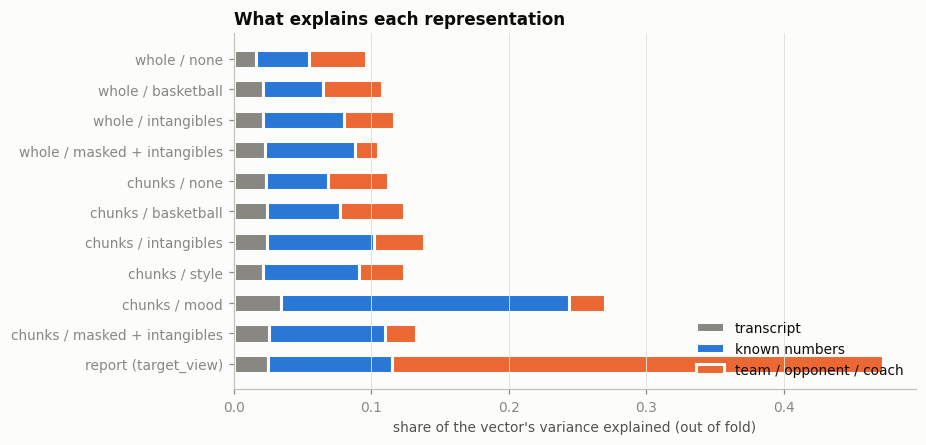

In [3]:
composition = pd.DataFrame({name: I.composition(frame, X) for name, (X, _, _) in representations.items()}).T
composition.loc["report (target_view)"] = I.composition(frame, report)
display(composition.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
names = list(composition.index)[::-1]
left = np.zeros(len(names))
for column, color, label in (("var_transcript", MUTED, "transcript"), ("var_known", BLUE, "known numbers"), ("var_identity", ORANGE, "team / opponent / coach")):
    values = composition.loc[names, column].clip(lower=0).to_numpy()
    ax.barh(names, values, left=left, color=color, label=label, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    left += values
ax.set(xlabel="share of the vector's variance explained (out of fold)", title="What explains each representation")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

## 3. Is the rest repeatable?

`removed` is cumulative: nothing → transcript → known numbers → identity
(team, opponent and coach dummies). `game` is the two-coaches AUC with its 95%
bootstrap interval over the games with both coaches; `halves` the same-presser
AUC (chunked representations only).

game: two coaches of the same game


removed,nothing,transcript,known,identity
whole / none,0.655,0.629,0.700,0.654
whole / basketball,0.650,0.623,0.714,0.650
whole / intangibles,0.588,0.565,0.686,0.630
whole / masked + intangibles,0.532,0.509,0.632,0.627
chunks / none,0.593,0.583,0.648,0.625
chunks / basketball,0.623,0.599,0.690,0.647
chunks / intangibles,0.535,0.527,0.644,0.616
chunks / style,0.552,0.540,0.634,0.605
chunks / mood,0.406,0.408,0.572,0.573
chunks / masked + intangibles,0.499,0.489,0.602,0.602


halves: odd and even chunks of the same presser


removed,nothing,transcript,known,identity
chunks / none,0.937,0.927,0.913,0.870
chunks / basketball,0.956,0.947,0.933,0.893
chunks / intangibles,0.943,0.936,0.918,0.878
chunks / style,0.930,0.922,0.902,0.859
chunks / mood,0.892,0.884,0.869,0.830
chunks / masked + intangibles,0.928,0.920,0.898,0.867


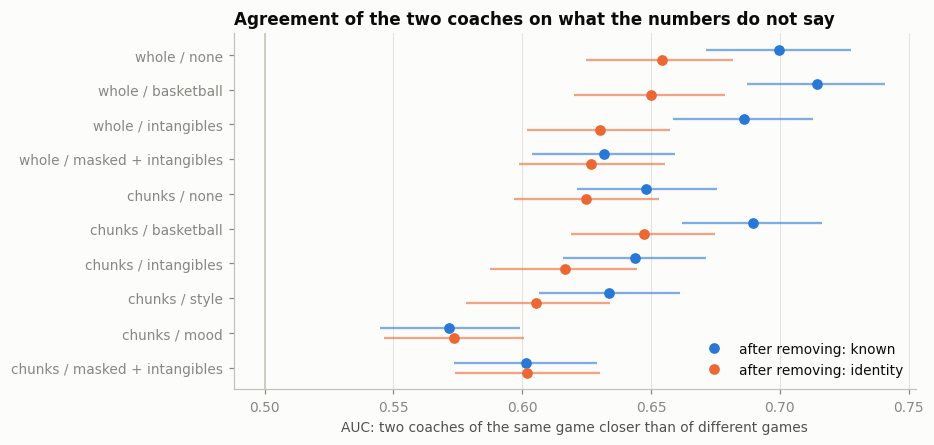

In [4]:
tables = {name: I.repeatability(frame, X, halves) for name, (X, halves, _) in representations.items()}
game = pd.DataFrame({name: table.set_index("removed")["game"] for name, table in tables.items()}).T
halves = pd.DataFrame({name: table.set_index("removed")["halves"] for name, table in tables.items() if "halves" in table}).T
print("game: two coaches of the same game"); display(game.round(3))
print("halves: odd and even chunks of the same presser"); display(halves.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
names = list(tables)[::-1]
for offset, level, color in ((0.15, "known", BLUE), (-0.15, "identity", ORANGE)):
    rows = pd.DataFrame({name: tables[name].set_index("removed").loc[level] for name in names}).T
    y = np.arange(len(names)) + offset
    ax.hlines(y, rows["game_low"], rows["game_high"], color=color, linewidth=1.5, alpha=0.6)
    ax.plot(rows["game"], y, "o", color=color, markersize=6, label=f"after removing: {level}")
ax.axvline(0.5, color="#c3c2b7", linewidth=1)
ax.set_yticks(range(len(names)), names)
ax.set(xlabel="AUC: two coaches of the same game closer than of different games", title="Agreement of the two coaches on what the numbers do not say")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

## 4. Concept anchors: named intangible axes

Instead of unnamed components, axes defined by short statements a coach could
make (`anchors.py`): the direction from the "low" pole to the "high" pole,
embedded under the `intangibles` instruction. A presser's score is the mean
projection of its chunks.

- `split_half_r`: odd against even chunks (is the score a property of the presser?).
- `r_won`, `r_length`, `r2_known`: how much of it is the result, the length, the numbers.
- `coaches_r_residual`: r between the two coaches of a game after removing
  the known numbers. Positive: they agree on the game ("it was physical").
  Negative: mirror images ("we had the energy" / "they had the energy").
- `coach_trait_r2`: share of the residual that is the coach's habit.

In [5]:
anchors = variants["anchors"]
directions = I.axis_directions(anchors, np.asarray(variants["vectors"]["anchors_intangibles"]))
axis_tables, axis_scores = {}, {}
for condition, text in (("intangibles", "raw"), ("masked_intangibles", "masked")):
    scores = I.axis_scores(variants["chunks"][text], variants["vectors"][f"chunks_{condition}"], directions)
    axis_scores[condition] = scores
    axis_tables[condition] = I.axis_report(frame, scores).set_index("axis")
    print(condition); display(axis_tables[condition].round(2))
print("Correlation between the axes (raw text)")
display(axis_scores["intangibles"]["all"].corr().round(2))

intangibles


,split_half_r,r_won,r_margin_vs_spread,r_length,r2_transcript,r2_known,coaches_r_raw,coaches_r_residual,coach_trait_r2
axis,,,,,,,,,
effort,0.74,0.68,0.67,0.22,0.05,0.58,-0.54,0.00,0.06
physicality,0.74,0.69,0.67,0.21,0.05,0.59,-0.54,0.01,0.05
ball_movement,0.72,0.68,0.66,0.21,0.04,0.57,-0.52,0.04,0.07
defensive_focus,0.74,0.70,0.67,0.21,0.04,0.58,-0.58,-0.04,0.07
tempo,0.39,0.45,0.46,0.19,0.05,0.33,-0.12,0.02,0.01
composure,0.76,0.70,0.66,0.24,0.06,0.59,-0.55,-0.00,0.07
satisfaction,0.74,0.70,0.68,0.22,0.04,0.60,-0.55,0.02,0.05
credit_to_opponent,0.63,0.61,0.60,0.21,0.04,0.46,-0.43,0.00,0.01


masked_intangibles


,split_half_r,r_won,r_margin_vs_spread,r_length,r2_transcript,r2_known,coaches_r_raw,coaches_r_residual,coach_trait_r2
axis,,,,,,,,,
effort,0.74,0.68,0.67,0.22,0.05,0.59,-0.54,0.01,0.06
physicality,0.73,0.69,0.67,0.22,0.05,0.60,-0.54,0.02,0.05
ball_movement,0.72,0.68,0.66,0.21,0.04,0.57,-0.51,0.03,0.06
defensive_focus,0.74,0.70,0.67,0.21,0.04,0.59,-0.58,-0.03,0.07
tempo,0.39,0.44,0.45,0.20,0.06,0.34,-0.12,0.01,0.00
composure,0.76,0.70,0.66,0.24,0.06,0.59,-0.55,-0.00,0.06
satisfaction,0.74,0.70,0.68,0.22,0.05,0.60,-0.55,0.02,0.05
credit_to_opponent,0.62,0.61,0.60,0.21,0.04,0.45,-0.43,-0.00,0.01


Correlation between the axes (raw text)


,effort,physicality,ball_movement,defensive_focus,tempo,composure,satisfaction,credit_to_opponent
effort,1.00,0.98,0.96,0.97,0.56,0.97,0.98,0.88
physicality,0.98,1.00,0.96,0.97,0.58,0.96,0.98,0.84
ball_movement,0.96,0.96,1.00,0.94,0.64,0.96,0.98,0.88
defensive_focus,0.97,0.97,0.94,1.00,0.48,0.97,0.97,0.89
tempo,0.56,0.58,0.64,0.48,1.00,0.53,0.61,0.63
composure,0.97,0.96,0.96,0.97,0.53,1.00,0.98,0.89
satisfaction,0.98,0.98,0.98,0.97,0.61,0.98,1.00,0.91
credit_to_opponent,0.88,0.84,0.88,0.89,0.63,0.89,0.91,1.00


Correlation between the axes after removing the known numbers


,effort,physicality,ball_movement,defensive_focus,tempo,composure,satisfaction,credit_to_opponent
effort,1.00,0.96,0.90,0.94,0.32,0.94,0.96,0.76
physicality,0.96,1.00,0.90,0.93,0.34,0.92,0.94,0.69
ball_movement,0.90,0.90,1.00,0.87,0.46,0.91,0.94,0.76
defensive_focus,0.94,0.93,0.87,1.00,0.20,0.94,0.94,0.78
tempo,0.32,0.34,0.46,0.20,1.00,0.28,0.41,0.48
composure,0.94,0.92,0.91,0.94,0.28,1.00,0.96,0.80
satisfaction,0.96,0.94,0.94,0.94,0.41,0.96,1.00,0.84
credit_to_opponent,0.76,0.69,0.76,0.78,0.48,0.80,0.84,1.00


Share of their variance per principal component: [0.81 0.12 0.04 0.01 0.01 0.01 0.   0.  ]


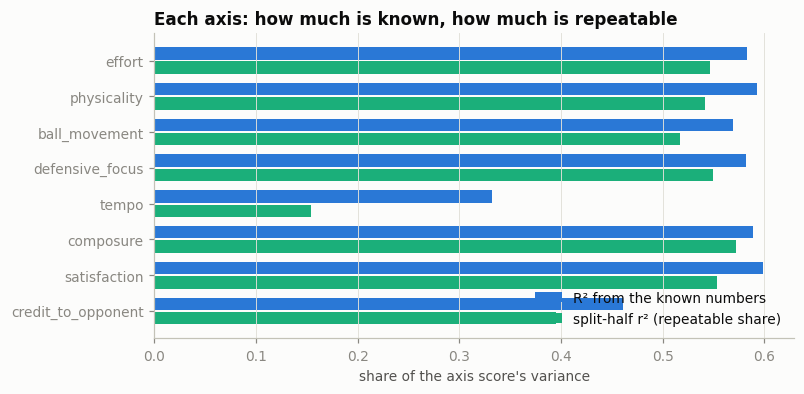

In [6]:
# The axes after removing the known numbers: are they one thing or several?
left = I.residual(axis_scores["intangibles"]["all"].to_numpy(), I.controls(frame, "known"))
left = pd.DataFrame(left, columns=axis_scores["intangibles"]["all"].columns)
print("Correlation between the axes after removing the known numbers")
display(left.corr().round(2))
values = np.linalg.eigvalsh(left.corr().to_numpy())[::-1]
print("Share of their variance per principal component:", (values / values.sum()).round(2))

table = axis_tables["intangibles"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(table))[::-1]
ax.barh(y + 0.2, table["r2_known"], height=0.35, color=BLUE, label="R² from the known numbers")
ax.barh(y - 0.2, table["split_half_r"] ** 2, height=0.35, color=AQUA, label="split-half r² (repeatable share)")
ax.set_yticks(y, table.index)
ax.set(xlabel="share of the axis score's variance", title="Each axis: how much is known, how much is repeatable")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

## 5. Against the news (NBA.com report) vectors

Same games, same team's point of view. How much of one source can be
predicted from the other, on top of the known numbers (out of fold, first 100
components of the predicted source; the other source enters as its first 64
components)?

In [7]:
groups = frame["game_id"].to_numpy()
known = np.hstack([I.controls(frame, "known")])
identity = np.hstack([A.one_hot(frame[name]) for name in ("team", "opponent", "coach")])
presser = chunk_means["intangibles"]["all"]
reduced = {"presser": A.pca(presser), "report": A.pca(report)}
rows = []
for target, other in (("presser", "report"), ("report", "presser")):
    blocks = {"known numbers": known, "identity": identity, f"{other} vector": reduced[other].scores[:, :64]}
    table = A.explained_by(reduced[target], blocks, groups)
    rows.append(table.set_index("features")["variance_explained"].rename(f"{target} explained by"))
    display(rows[-1].round(3).to_frame())

# Same-game agreement between the two sources, after removing the known part.
for level in I.LEVELS:
    C = I.controls(frame, level)
    rates = I.matched_rates(I.residual(presser, C), I.residual(report, C))
    low, high = I.interval(rates)
    print(f"presser vs report of the same game and team, removed {level:10s}: AUC {rates.mean():.3f} [{low:.3f}, {high:.3f}]")

,presser explained by
features,
known numbers,0.102
+ identity,0.139
+ report vector,0.158


,report explained by
features,
known numbers,0.115
+ identity,0.472
+ presser vector,0.477


presser vs report of the same game and team, removed nothing   : AUC 0.932 [0.924, 0.940]


presser vs report of the same game and team, removed transcript: AUC 0.934 [0.926, 0.941]


presser vs report of the same game and team, removed known     : AUC 0.916 [0.907, 0.925]


presser vs report of the same game and team, removed identity  : AUC 0.845 [0.832, 0.857]


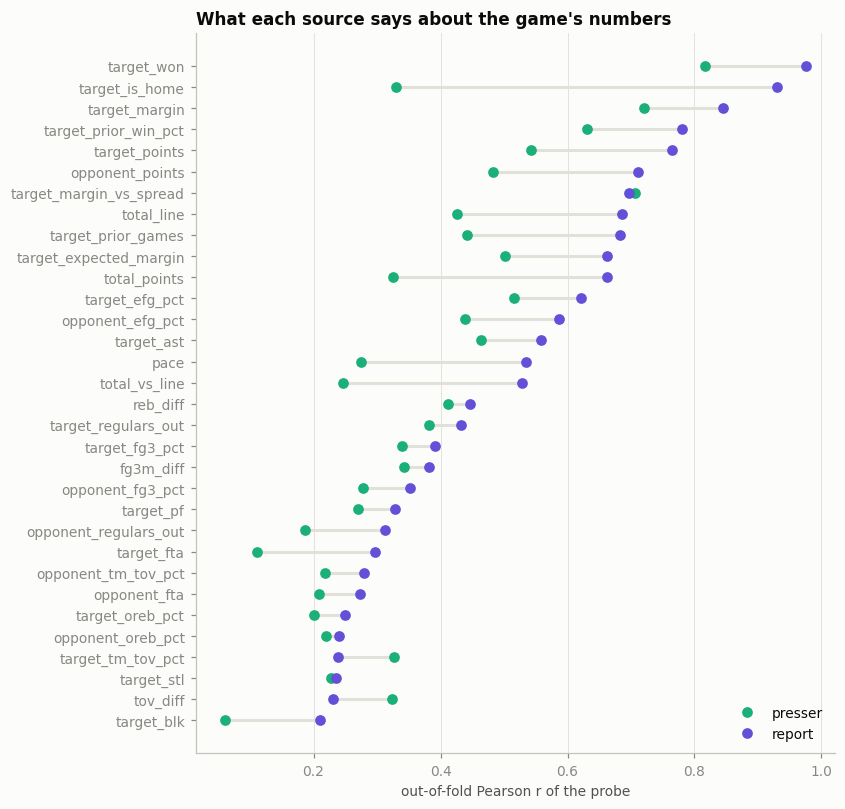

,presser (chunks / intangibles),report (target_view)
label,,
target_won,0.816,0.975
target_margin,0.721,0.845
target_points,0.542,0.764
opponent_points,0.482,0.712
total_points,0.325,0.661
pace,0.276,0.535
target_efg_pct,0.516,0.621
target_fg3_pct,0.340,0.392
target_fta,0.112,0.297


In [8]:
# The same statistics read from each source (full vector, out of fold).
labels = A.label_names()
probes = pd.DataFrame({
    "presser (chunks / intangibles)": A.probe(presser, frame, labels).set_index("label")["r"],
    "report (target_view)": A.probe(report, frame, labels).set_index("label")["r"],
})
order = probes["report (target_view)"].sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 8.5))
y = np.arange(len(order))
ax.hlines(y, probes.loc[order].min(1), probes.loc[order].max(1), color=GRID, linewidth=2)
ax.plot(probes.loc[order, "presser (chunks / intangibles)"], y, "o", color=AQUA, markersize=6, label="presser")
ax.plot(probes.loc[order, "report (target_view)"], y, "o", color=VIOLET, markersize=6, label="report")
ax.set_yticks(y, order)
ax.set(xlabel="out-of-fold Pearson r of the probe", title="What each source says about the game's numbers")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()
display(probes.round(3))

Do the two coaches agree on something the news does not already say? The
`game` AUC again, after also removing the report vector of the game (its
first 64 components) on top of the known numbers and identity.

In [9]:
home, away = I.game_pairs(frame)
report_block = A.pca(report).scores[:, :64]
rows = []
for name in ("whole / none", "whole / basketball", "chunks / basketball", "whole / masked + intangibles"):
    X = representations[name][0]
    for label, C in (
        ("known + identity", I.controls(frame, "identity")),
        ("known + identity + report", np.hstack([I.controls(frame, "identity"), report_block])),
    ):
        left = I.residual(X, C)
        rates = I.matched_rates(left[home], left[away])
        low, high = I.interval(rates)
        rows.append({"representation": name, "removed": label, "game": rates.mean(), "low": low, "high": high})
display(pd.DataFrame(rows).round(3))
print("Intervals of the game AUC in section 3 (after removing the known numbers):")
display(pd.DataFrame({name: tables[name].set_index("removed").loc["known", ["game", "game_low", "game_high"]] for name in tables}).T.round(3))

,representation,removed,game,low,high
0,whole / none,known + identity,0.654,0.625,0.682
1,whole / none,known + identity + report,0.434,0.403,0.464
2,whole / basketball,known + identity,0.650,0.620,0.679
3,whole / basketball,known + identity + report,0.420,0.390,0.450
4,chunks / basketball,known + identity,0.647,0.619,0.675
5,chunks / basketball,known + identity + report,0.446,0.417,0.477
6,whole / masked + intangibles,known + identity,0.627,0.599,0.655
7,whole / masked + intangibles,known + identity + report,0.421,0.391,0.451


Intervals of the game AUC in section 3 (after removing the known numbers):


,game,game_low,game_high
whole / none,0.700,0.671,0.727
whole / basketball,0.714,0.687,0.741
whole / intangibles,0.686,0.659,0.713
whole / masked + intangibles,0.632,0.604,0.659
chunks / none,0.648,0.621,0.676
chunks / basketball,0.690,0.662,0.716
chunks / intangibles,0.644,0.616,0.671
chunks / style,0.634,0.607,0.661
chunks / mood,0.572,0.545,0.599
chunks / masked + intangibles,0.602,0.574,0.629
